In [44]:

import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt

In [45]:
print("Loading Dataset...")
BASE_DIR = Path.cwd().resolve().parent
DATASET_PATH = BASE_DIR / "docs" / "dataset" / "cleaned_blockchain_tx_dataset.csv"
df = pd.read_csv(DATASET_PATH)
print(f"Dataset Loaded Successfully! Initial Shape: {df.shape}\n")

Loading Dataset...
Dataset Loaded Successfully! Initial Shape: (1155323, 35)



In [47]:
df.dtypes

hash                             object
nonce                             int64
transaction_index                 int64
from_address                     object
to_address                       object
value                           float64
gas                               int64
gas_price                         int64
receipt_gas_used                  int64
receipt_cumulative_gas_used       int64
block_timestamp                  object
block_number                      int64
receipt_status                    int64
is_contract_call                  int64
receipt_contract_address         object
max_fee_per_gas                 float64
max_priority_fee_per_gas        float64
from_is_contract                  int64
to_is_contract                    int64
from_address_age_seconds          int64
to_address_age_seconds          float64
receiver_is_newly_created       float64
time_since_last_sent_tx         float64
avg_time_between_sent_tx        float64
sent_tx_count_so_far              int64


In [48]:
df['from_address']=df['from_address'].astype('string')
df['to_address']=df['to_address'].astype('string')
df['value']=df['value'].astype('float64')
df['gas']=df['gas'].astype('int64')
df['gas_price']=df['gas_price'].astype('float64')
df['receipt_gas_used']=df['receipt_gas_used'].astype('int64')
df['receipt_cumulative_gas_used']=df['receipt_cumulative_gas_used'].astype('int64')
df['block_timestamp']=pd.to_datetime(df['block_timestamp'],format='%Y-%m-%d %H:%M:%S UTC',errors='coerce')
df['block_number']=df['block_number'].astype('int64')
df['receipt_status']=df['receipt_status'].astype('int8')
df['is_contract_call']=df['is_contract_call'].astype('int8')
df['receipt_contract_address']=df['receipt_contract_address'].astype('string')
df['max_fee_per_gas']=df['max_fee_per_gas'].astype('float64')
df['max_priority_fee_per_gas']=df['max_priority_fee_per_gas'].astype('float64')
df['from_is_contract']=df['from_is_contract'].astype('int8')
df['to_is_contract']=df['to_is_contract'].astype('int8')
df['receiver_is_newly_created']=df['receiver_is_newly_created'].astype('int8')
df['hash']=df['hash'].astype('string')
print(df.dtypes)


hash                            string[python]
nonce                                    int64
transaction_index                        int64
from_address                    string[python]
to_address                      string[python]
value                                  float64
gas                                      int64
gas_price                              float64
receipt_gas_used                         int64
receipt_cumulative_gas_used              int64
block_timestamp                 datetime64[ns]
block_number                             int64
receipt_status                            int8
is_contract_call                          int8
receipt_contract_address        string[python]
max_fee_per_gas                        float64
max_priority_fee_per_gas               float64
from_is_contract                          int8
to_is_contract                            int8
from_address_age_seconds                 int64
to_address_age_seconds                 float64
receiver_is_n

In [49]:
print(list(df.columns))

['hash', 'nonce', 'transaction_index', 'from_address', 'to_address', 'value', 'gas', 'gas_price', 'receipt_gas_used', 'receipt_cumulative_gas_used', 'block_timestamp', 'block_number', 'receipt_status', 'is_contract_call', 'receipt_contract_address', 'max_fee_per_gas', 'max_priority_fee_per_gas', 'from_is_contract', 'to_is_contract', 'from_address_age_seconds', 'to_address_age_seconds', 'receiver_is_newly_created', 'time_since_last_sent_tx', 'avg_time_between_sent_tx', 'sent_tx_count_so_far', 'avg_value_sent_so_far', 'std_value_sent_so_far', 'value_zscore', 'gas_price_deviation', 'failed_tx_ratio', 'avg_time_between_received_tx', 'received_tx_count_so_far', 'avg_value_received_so_far', 'first_sent_tx', 'first_received_tx']


In [10]:
df.sample(5)

,hash,nonce,transaction_index,from_address,to_address,value,gas,gas_price,receipt_gas_used,receipt_cumulative_gas_used,...,avg_value_sent_so_far,std_value_sent_so_far,value_zscore,gas_price_deviation,failed_tx_ratio,avg_time_between_received_tx,received_tx_count_so_far,avg_value_received_so_far,first_sent_tx,first_received_tx
712378,0xd849d8f10e410a6d42eed7b3706241ef86d68336dd97...,243,276,0x98cb129fbb5f792c9435e31368a2d66b99ca26c1,0x8b634b2ae70e338865bf9741b4ae935adf2b4c55,0.000000e+00,160924,5.833268e+10,97530,19410057,...,0.0,0.0,0.0,0.000000e+00,0.0,23.384615,14,0.0,1,0
245444,0x041e24f83cbd448137d7ac0049749c4699bf67b47213...,835,102,0x4f6d85981c5ff66a807da3e6d5552b48a4140127,0x7a0b204afb1bc2a0488d0ddd815941dfe3d5c05b,9.000000e+16,21000,1.954360e+10,21000,16267158,...,0.0,0.0,0.0,0.000000e+00,0.0,-1.000000,0,0.0,1,1
635132,0x66dd8cab80325f0e9460a81b7359bb592b641ff680d7...,13,101,0x333d0142c44859ecc9c979877397ab02a2c2e83c,0x7bef710a5759d197ec0bf621c3df802c2d60d848,0.000000e+00,55774,1.700000e+10,46479,6523770,...,0.0,0.0,0.0,0.000000e+00,0.0,36385.200000,6,0.0,1,0
898946,0x0ba0adc8f02f3d9697e44a40b6d670d73527b8c5d6cb...,55,80,0x8270b6f624170e9d76fc9edae1a4752b328806e6,0x9b4e2b4b13d125238aa0480dd42b4f6fc71b37cc,0.000000e+00,60000,2.000000e+10,51606,4269185,...,0.0,0.0,0.0,0.000000e+00,0.0,2638.000000,7,0.0,1,0
838906,0x92bd3cca59762c29bee4a27b7a53e8b65fb7a70ecd1f...,390,180,0x31a74e546b350237804a40bf97add2388c83ce28,0x974664931d760f9e6439b0d6b1c692390a844978,4.500000e+16,21000,2.511365e+10,21000,13494766,...,0.0,0.0,0.0,7.356928e+09,0.0,-1.000000,0,0.0,0,1


In [54]:
missing = df.isna().sum()

print("Total Missing Values:", missing.sum())
print("\nMissing Values by Column:")
print(missing[missing > 0])

Total Missing Values: 0

Missing Values by Column:
Series([], dtype: int64)


In [55]:
numeric_cols=df.select_dtypes(include='number')
total_infinity=np.isinf(numeric_cols).sum().sum()
print(f"Total Infinity Values: {total_infinity}")

Total Infinity Values: 0


In [56]:
df.describe()

,nonce,transaction_index,value,gas,gas_price,receipt_gas_used,receipt_cumulative_gas_used,block_timestamp,block_number,receipt_status,...,avg_value_sent_so_far,std_value_sent_so_far,value_zscore,gas_price_deviation,failed_tx_ratio,avg_time_between_received_tx,received_tx_count_so_far,avg_value_received_so_far,first_sent_tx,first_received_tx
count,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1155323,1.155323e+06,1.155323e+06,...,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06,1.155323e+06
mean,7.174458e+03,1.017373e+02,2.584826e+18,1.909678e+05,3.213116e+10,7.980866e+04,7.075599e+06,2021-02-07 15:37:46.487581952,1.187255e+07,9.699971e-01,...,9.634472e+17,1.231975e+18,2.045774e+11,3.447855e+07,1.568628e-02,1.842239e+05,3.186185e+01,8.944445e+17,5.838532e-01,4.653339e-01
min,0.000000e+00,0.000000e+00,0.000000e+00,2.100000e+04,0.000000e+00,1.312800e+04,1.318200e+04,2018-06-01 00:00:00,5.710964e+06,0.000000e+00,...,0.000000e+00,0.000000e+00,-1.053560e+07,-6.947516e+12,0.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,7.000000e+00,4.500000e+01,0.000000e+00,2.100000e+04,1.400000e+10,2.100000e+04,2.799584e+06,2019-06-10 21:57:36,7.933698e+06,1.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,8.600000e+01,8.900000e+01,1.495518e+07,5.477000e+04,2.331164e+10,2.520000e+04,5.899574e+06,2021-06-05 07:01:56,1.257302e+07,1.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,3.156000e+01,3.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00
75%,1.119000e+03,1.410000e+02,5.556258e+16,1.220430e+05,3.996779e+10,5.713200e+04,9.493074e+06,2022-06-10 03:12:34,1.493618e+07,1.000000e+00,...,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.250921e+04,3.500000e+01,0.000000e+00,1.000000e+00,1.000000e+00
max,1.572145e+06,1.312000e+03,7.609000e+22,2.988840e+07,5.400737e+13,2.988840e+07,3.014470e+07,2023-06-14 23:59:47,1.748159e+07,1.000000e+00,...,1.249999e+22,8.838814e+21,1.003439e+17,2.233076e+13,1.000000e+00,1.573184e+08,4.220000e+02,1.500000e+22,1.000000e+00,1.000000e+00
std,2.995336e+04,7.649826e+01,1.246895e+20,8.154475e+05,1.065443e+11,3.645855e+05,5.810750e+06,NaN,3.999457e+06,1.705952e-01,...,3.270006e+19,3.083728e+19,1.248378e+14,6.008426e+10,9.778274e-02,1.584464e+06,5.960233e+01,3.493406e+19,4.929187e-01,4.987970e-01


In [57]:
df.select_dtypes(include="number").skew()

nonce                             9.762397
transaction_index                 1.542003
value                           301.343703
gas                              16.585828
gas_price                       307.599082
receipt_gas_used                 34.441739
receipt_cumulative_gas_used       1.461667
block_number                     -0.127985
receipt_status                   -5.510096
is_contract_call                 -0.126278
max_fee_per_gas                 170.743526
max_priority_fee_per_gas        190.218963
from_is_contract                  0.000000
to_is_contract                   -0.178358
from_address_age_seconds          5.307109
to_address_age_seconds            4.957091
receiver_is_newly_created        -0.312005
time_since_last_sent_tx          11.384758
avg_time_between_sent_tx         20.611754
sent_tx_count_so_far              4.364724
avg_value_sent_so_far           133.202216
std_value_sent_so_far           109.030973
value_zscore                    740.470449
gas_price_d

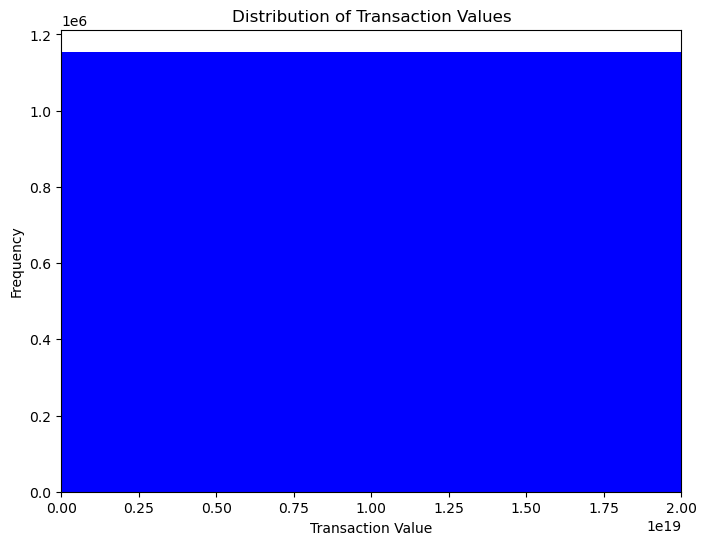

In [58]:
plt.figure(figsize=(8,6))
upper_limit = df["value"].quantile(0.99)
plt.hist(df['value'],bins=100 ,color='blue')
plt.xlim(0, upper_limit)
plt.ylabel("Frequency")
plt.title('Distribution of Transaction Values')
plt.xlabel('Transaction Value')
plt.ylabel('Frequency')
plt.show()

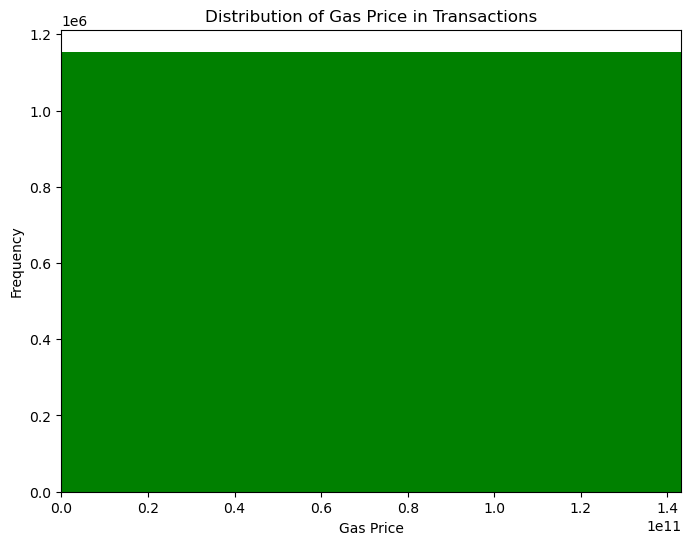

In [59]:
upper_limit = df["gas_price"].quantile(0.99)
plt.figure(figsize=(8, 6))
plt.xlim(0, upper_limit)
plt.hist(df['gas_price'],bins=100,color='green')
plt.title('Distribution of Gas Price in Transactions')
plt.xlabel('Gas Price')
plt.ylabel('Frequency')
plt.show()

In [60]:
numeric_cols = df.select_dtypes(include="number").columns

print("Total numerical features:", len(numeric_cols))
print("\nAll numerical features:")
print(numeric_cols.tolist())

Total numerical features: 30

All numerical features:
['nonce', 'transaction_index', 'value', 'gas', 'gas_price', 'receipt_gas_used', 'receipt_cumulative_gas_used', 'block_number', 'receipt_status', 'is_contract_call', 'max_fee_per_gas', 'max_priority_fee_per_gas', 'from_is_contract', 'to_is_contract', 'from_address_age_seconds', 'to_address_age_seconds', 'receiver_is_newly_created', 'time_since_last_sent_tx', 'avg_time_between_sent_tx', 'sent_tx_count_so_far', 'avg_value_sent_so_far', 'std_value_sent_so_far', 'value_zscore', 'gas_price_deviation', 'failed_tx_ratio', 'avg_time_between_received_tx', 'received_tx_count_so_far', 'avg_value_received_so_far', 'first_sent_tx', 'first_received_tx']


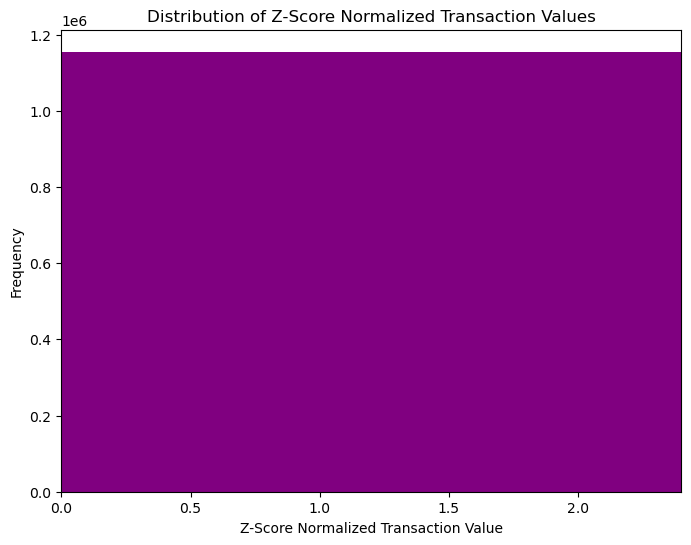

In [61]:
upper_limit = df["value_zscore"].quantile(0.99)
plt.figure(figsize=(8, 6))
plt.hist(df['value_zscore'], bins=100, color='purple')
plt.xlim(0, upper_limit)
plt.title('Distribution of Z-Score Normalized Transaction Values')
plt.xlabel('Z-Score Normalized Transaction Value')
plt.ylabel('Frequency')
plt.show()

In [62]:
print("Zero values:", (df["value_zscore"] == 0).sum())
print("Negative values:", (df["value_zscore"] < 0).sum())
print("Positive values:", (df["value_zscore"] > 0).sum())

Zero values: 986196
Negative values: 120228
Positive values: 48899


In [63]:
binary_cols=[   "receipt_status",
    "is_contract_call",
    "from_is_contract",
    "to_is_contract",
    "receiver_is_newly_created",
    "first_sent_tx",
    "first_received_tx"]

In [64]:
for col in binary_cols:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


receipt_status
receipt_status
1    1120660
0      34663
Name: count, dtype: int64

is_contract_call
is_contract_call
1    614062
0    541261
Name: count, dtype: int64

from_is_contract
from_is_contract
0    1155323
Name: count, dtype: int64

to_is_contract
to_is_contract
1    628973
0    526350
Name: count, dtype: int64

receiver_is_newly_created
receiver_is_newly_created
1    666701
0    488622
Name: count, dtype: int64

first_sent_tx
first_sent_tx
1    674539
0    480784
Name: count, dtype: int64

first_received_tx
first_received_tx
0    617712
1    537611
Name: count, dtype: int64


In [65]:
df["from_is_contract"].nunique()


1

The `from_is_contract` feature contains only one unique value (0) across the entire dataset. Since it has zero variance and provides no distinguishing information, it will be excluded from the model input features.

In [66]:
sentinel_cols = [
    "time_since_last_sent_tx",
    "avg_time_between_sent_tx",
    "avg_time_between_received_tx"
]
for col in sentinel_cols:
    print(f"\n{col}")
    print("Negative values:", (df[col] < 0).sum())
    print("Minus one values:", (df[col] == -1).sum())


time_since_last_sent_tx
Negative values: 674539
Minus one values: 674539

avg_time_between_sent_tx
Negative values: 784691
Minus one values: 784691

avg_time_between_received_tx
Negative values: 537611
Minus one values: 537611


In [67]:
col = "avg_time_between_received_tx"

print("Negative values:", (df[col] < 0).sum())
print("Minus one values:", (df[col] == -1).sum())

Negative values: 537611
Minus one values: 537611


Teeno features mein negative values sirf -1 hain. Yeh likely indicate karta hai ke relevant previous transaction history available nahi thi.

The three behavioural features (`time_since_last_sent_tx`, `avg_time_between_sent_tx`, and `avg_time_between_received_tx`) contain -1 as a sentinel value. These values likely indicate unavailable historical transaction information. No other negative values were identified in these features. 

In [68]:
print(df.columns.tolist())

['hash', 'nonce', 'transaction_index', 'from_address', 'to_address', 'value', 'gas', 'gas_price', 'receipt_gas_used', 'receipt_cumulative_gas_used', 'block_timestamp', 'block_number', 'receipt_status', 'is_contract_call', 'receipt_contract_address', 'max_fee_per_gas', 'max_priority_fee_per_gas', 'from_is_contract', 'to_is_contract', 'from_address_age_seconds', 'to_address_age_seconds', 'receiver_is_newly_created', 'time_since_last_sent_tx', 'avg_time_between_sent_tx', 'sent_tx_count_so_far', 'avg_value_sent_so_far', 'std_value_sent_so_far', 'value_zscore', 'gas_price_deviation', 'failed_tx_ratio', 'avg_time_between_received_tx', 'received_tx_count_so_far', 'avg_value_received_so_far', 'first_sent_tx', 'first_received_tx']


In [69]:
scaling_cols = [
    "nonce",
    "value",
    "gas",
    "gas_price",
    "receipt_gas_used",
    "receipt_cumulative_gas_used",
    "max_fee_per_gas",
    "max_priority_fee_per_gas",
    "from_address_age_seconds",
    "to_address_age_seconds",
    "avg_time_between_received_tx",
    "received_tx_count_so_far",
    "avg_value_received_so_far"
]

df[scaling_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
nonce,1155323.0,7.174458e+03,2.995336e+04,0.000000e+00,7.000000e+00,8.600000e+01,1.119000e+03,1.572145e+06
value,1155323.0,2.584826e+18,1.246895e+20,0.000000e+00,0.000000e+00,1.495518e+07,5.556258e+16,7.609000e+22
gas,1155323.0,1.909678e+05,8.154475e+05,2.100000e+04,2.100000e+04,5.477000e+04,1.220430e+05,2.988840e+07
gas_price,1155323.0,3.213116e+10,1.065443e+11,0.000000e+00,1.400000e+10,2.331164e+10,3.996779e+10,5.400737e+13
receipt_gas_used,1155323.0,7.980866e+04,3.645855e+05,1.312800e+04,2.100000e+04,2.520000e+04,5.713200e+04,2.988840e+07
receipt_cumulative_gas_used,1155323.0,7.075599e+06,5.810750e+06,1.318200e+04,2.799584e+06,5.899574e+06,9.493074e+06,3.014470e+07
max_fee_per_gas,1155323.0,5.867274e+10,1.422235e+11,1.300000e+10,5.002175e+10,5.002175e+10,5.002175e+10,5.151529e+13
max_priority_fee_per_gas,1155323.0,3.475947e+09,5.555362e+10,0.000000e+00,1.500000e+09,1.500000e+09,1.500000e+09,2.311809e+13
from_address_age_seconds,1155323.0,3.495840e+06,1.358793e+07,0.000000e+00,0.000000e+00,0.000000e+00,2.958360e+05,1.589222e+08
to_address_age_seconds,1155323.0,3.934820e+06,1.438552e+07,-1.000000e+00,0.000000e+00,7.041000e+03,5.108860e+05,1.589659e+08


In [70]:
for col in scaling_cols:
    zero_count = (df[col] == 0).sum()
    zero_percentage = (zero_count / len(df)) * 100

    print(
        f"{col}: {zero_count:,} "
        f"({zero_percentage:.2f}%)"
    )

nonce: 95,622 (8.28%)
value: 574,743 (49.75%)
gas: 0 (0.00%)
gas_price: 4,176 (0.36%)
receipt_gas_used: 0 (0.00%)
receipt_cumulative_gas_used: 0 (0.00%)
max_fee_per_gas: 0 (0.00%)
max_priority_fee_per_gas: 3,061 (0.26%)
from_address_age_seconds: 676,178 (58.53%)
to_address_age_seconds: 477,901 (41.37%)
avg_time_between_received_tx: 2,322 (0.20%)
received_tx_count_so_far: 478,847 (41.45%)
avg_value_received_so_far: 922,507 (79.85%)


In [31]:
log_cols = [
    "nonce",
    "value",
    "gas",
    "receipt_gas_used",
    "max_fee_per_gas",
    "from_address_age_seconds",
    "received_tx_count_so_far",
    "avg_value_received_so_far"
]

In [32]:
df_transformed = df.copy()
df_transformed[log_cols] = np.log1p(df_transformed[log_cols])

In [33]:
df_transformed[log_cols].skew().sort_values(ascending=False)

max_fee_per_gas              1.779037
receipt_gas_used             1.657693
avg_value_received_so_far    1.550980
gas                          1.124874
from_address_age_seconds     0.560086
received_tx_count_so_far     0.464514
nonce                        0.359872
value                        0.035026
dtype: float64

In [76]:
sentinel_cols = [
    "time_since_last_sent_tx",
    "avg_time_between_sent_tx",
    "avg_time_between_received_tx",
    "to_address_age_seconds"
]

In [77]:
for col in sentinel_cols:
    print(
        col,
        "Missing:",
        df_transformed[col].isna().sum(),
        "Indicator:",
        df_transformed[f"{col}_missing"].sum()
    )

time_since_last_sent_tx Missing: 674539 Indicator: 0
avg_time_between_sent_tx Missing: 784691 Indicator: 0
avg_time_between_received_tx Missing: 537611 Indicator: 0
to_address_age_seconds Missing: 4008 Indicator: 0


In [75]:
print("Dataset Shape:", df_transformed.shape)

print("\nAvailable Columns:")
print(df_transformed.columns.tolist())

print("\nMissing Values:")
print(df_transformed.isna().sum().sum())

Dataset Shape: (1155323, 39)

Available Columns:
['hash', 'nonce', 'transaction_index', 'from_address', 'to_address', 'value', 'gas', 'gas_price', 'receipt_gas_used', 'receipt_cumulative_gas_used', 'block_timestamp', 'block_number', 'receipt_status', 'is_contract_call', 'receipt_contract_address', 'max_fee_per_gas', 'max_priority_fee_per_gas', 'from_is_contract', 'to_is_contract', 'from_address_age_seconds', 'to_address_age_seconds', 'receiver_is_newly_created', 'time_since_last_sent_tx', 'avg_time_between_sent_tx', 'sent_tx_count_so_far', 'avg_value_sent_so_far', 'std_value_sent_so_far', 'value_zscore', 'gas_price_deviation', 'failed_tx_ratio', 'avg_time_between_received_tx', 'received_tx_count_so_far', 'avg_value_received_so_far', 'first_sent_tx', 'first_received_tx', 'time_since_last_sent_tx_missing', 'avg_time_between_sent_tx_missing', 'avg_time_between_received_tx_missing', 'to_address_age_seconds_missing']

Missing Values:
2000849


In [79]:
print("Duplicate Columns:",
      df_transformed.columns.duplicated().sum())

print("Duplicate Rows:",
      df_transformed.duplicated().sum())

Duplicate Columns: 0
Duplicate Rows: 0


In [81]:
df_transformed.dtypes

hash                                    string[python]
nonce                                          float64
transaction_index                                int64
from_address                            string[python]
to_address                              string[python]
value                                          float64
gas                                            float64
gas_price                                      float64
receipt_gas_used                               float64
receipt_cumulative_gas_used                      int64
block_timestamp                         datetime64[ns]
block_number                                     int64
receipt_status                                    int8
is_contract_call                                  int8
receipt_contract_address                string[python]
max_fee_per_gas                                float64
max_priority_fee_per_gas                       float64
from_is_contract                                  int8
to_is_cont

In [82]:
numeric_df = df_transformed.select_dtypes(include=np.number)

print("Total Infinite Values:",
      np.isinf(numeric_df).sum().sum())

Total Infinite Values: 0


In [78]:
# Create output directory
OUTPUT_DIR = BASE_DIR / "docs" / "dataset" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Export transformed training dataset
OUTPUT_PATH = OUTPUT_DIR / "ethereum_training_preprocessed.csv"

df_transformed.to_csv(
    OUTPUT_PATH,
    index=False
)

# Confirm export
print("Dataset exported successfully!")
print("File:", OUTPUT_PATH)
print("Shape:", df_transformed.shape)
print("File Size:", round(OUTPUT_PATH.stat().st_size / (1024**2), 2), "MB")

Dataset exported successfully!
File: C:\Users\Ahmad Munir Sheikh\OneDrive\Desktop\FYP(Explainable AI for Blockchain Fraud Detection)\docs\dataset\processed\ethereum_training_preprocessed.csv
Shape: (1155323, 39)
File Size: 479.43 MB
